In [1]:
from pathlib import Path

from nn import NeuralNetwork, train
from data import make_runge_data
from optimizers import GD, RMSprop, Adam
from sklearn.model_selection import train_test_split
import numpy as np
import matplotlib.pyplot as plt

project_root = Path.cwd().parent if Path.cwd().name == "Code" else Path.cwd()
figures_dir = project_root / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

In [2]:
#create Runge data and standardize it
X_train, X_test, y_train, y_test = make_runge_data(100, 0.1, 0.2, 2026)
X_train, X_val,y_train, y_val = train_test_split(X_train, y_train, test_size = 0.25, random_state = 2026)

x_mean = X_train.mean(axis=0)
x_std = X_train.std(axis = 0)

X_train = (X_train - x_mean)/x_std
X_val = (X_val - x_mean)/x_std
X_test = (X_test - x_mean)/x_std

mean = y_train.mean()
y_train -= mean
y_val -= mean
y_test -= mean

In [3]:
### First architecture ###
layer_sizes = [1, 50, 1]
activations = ["sigmoid", "identity"]

In [4]:
### The optimizers, batch sizes and learning rates ###
trials = [(Adam, 16), (RMSprop, 16), (GD, None)]
learning_rates = np.geomspace(1e-3, 1, 10)

In [5]:
epochs = 10000
results = {}

for optimizer_class, batch_size in trials:
    best_mses = []
    for gamma in learning_rates:
        # New network for each combination
        nn_model = NeuralNetwork(layer_sizes, activations)
        optimizer = optimizer_class(gamma)

        error_history = train(nn_model, optimizer, X_train, y_train, epochs, batch_size, X_val=X_val, y_val=y_val)

        val_errors = np.array(error_history["val"])

        if np.any(np.isfinite(val_errors)):
            best_mse = np.nanmin(val_errors)
            best_epoch = np.nanargmin(val_errors) + 1
        else:
            best_mse = np.nan
            best_epoch = None

        best_mses.append(best_mse)

        print(
            f"{optimizer_class.__name__:8s} | "
            f"M = {str(batch_size):4s} | "
            f"gamma = {gamma:.5f} | "
            f"Best val MSE = {best_mse:.6f} | "
            f"Epoch = {best_epoch}"
        )

    results[optimizer_class.__name__] = best_mses

Adam     | M = 16   | gamma = 0.00100 | Best val MSE = 0.013200 | Epoch = 1184
Adam     | M = 16   | gamma = 0.00215 | Best val MSE = 0.012591 | Epoch = 585
Adam     | M = 16   | gamma = 0.00464 | Best val MSE = 0.012319 | Epoch = 363
Adam     | M = 16   | gamma = 0.01000 | Best val MSE = 0.011901 | Epoch = 130
Adam     | M = 16   | gamma = 0.02154 | Best val MSE = 0.011545 | Epoch = 380
Adam     | M = 16   | gamma = 0.04642 | Best val MSE = 0.011466 | Epoch = 843
Adam     | M = 16   | gamma = 0.10000 | Best val MSE = 0.011108 | Epoch = 107
Adam     | M = 16   | gamma = 0.21544 | Best val MSE = 0.011346 | Epoch = 621
Adam     | M = 16   | gamma = 0.46416 | Best val MSE = 0.010864 | Epoch = 621
Adam     | M = 16   | gamma = 1.00000 | Best val MSE = 0.013459 | Epoch = 1971
RMSprop  | M = 16   | gamma = 0.00100 | Best val MSE = 0.013090 | Epoch = 1182
RMSprop  | M = 16   | gamma = 0.00215 | Best val MSE = 0.012659 | Epoch = 3322
RMSprop  | M = 16   | gamma = 0.00464 | Best val MSE = 0.011

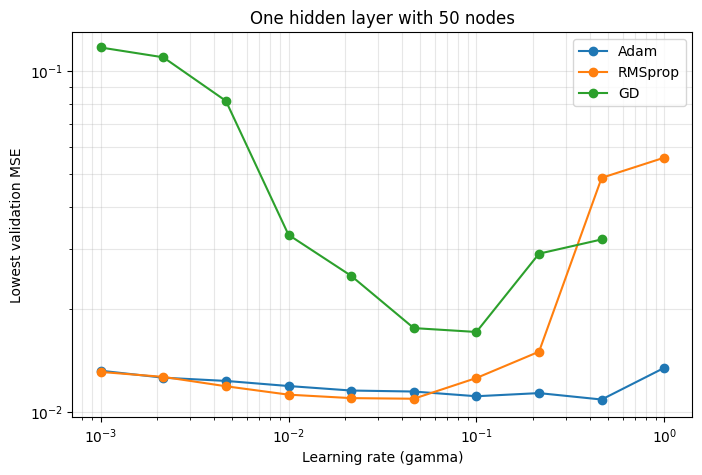

In [6]:
# Plot lowest validation MSE vs learning rate
fig, ax = plt.subplots(figsize=(8, 5))

for optimizer_name, best_mses in results.items():
    best_mses = np.array(best_mses)

    # Only plot valid MSE values below 1
    mask = np.isfinite(best_mses) & (best_mses < 1)

    ax.plot(learning_rates[mask], best_mses[mask], marker="o", label=optimizer_name)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_ylim(top=0.13)
ax.set_xlabel("Learning rate (gamma)")
ax.set_ylabel("Lowest validation MSE")
ax.set_title("One hidden layer with 50 nodes")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
fig.savefig(figures_dir / "part_b_learning_rate_1_50_1.pdf", bbox_inches="tight")
plt.show()

In [7]:
### Second architecture ###
layer_sizes = [1, 100, 100, 1]
activations = ["sigmoid", "sigmoid", "identity"]

In [8]:
epochs = 10000
results = {}

for optimizer_class, batch_size in trials:
    best_mses = []
    for gamma in learning_rates:
        # New network for each combination
        nn_model = NeuralNetwork(layer_sizes, activations)
        optimizer = optimizer_class(gamma)

        error_history = train(nn_model, optimizer, X_train, y_train, epochs, batch_size, X_val=X_val, y_val=y_val)

        val_errors = np.array(error_history["val"])

        if np.any(np.isfinite(val_errors)):
            best_mse = np.nanmin(val_errors)
            best_epoch = np.nanargmin(val_errors) + 1
        else:
            best_mse = np.nan
            best_epoch = None

        best_mses.append(best_mse)

        print(
            f"{optimizer_class.__name__:8s} | "
            f"M = {str(batch_size):4s} | "
            f"gamma = {gamma:.5f} | "
            f"Best val MSE = {best_mse:.6f} | "
            f"Epoch = {best_epoch}"
        )

    results[optimizer_class.__name__] = best_mses

Adam     | M = 16   | gamma = 0.00100 | Best val MSE = 0.010225 | Epoch = 363
Adam     | M = 16   | gamma = 0.00215 | Best val MSE = 0.010403 | Epoch = 159
Adam     | M = 16   | gamma = 0.00464 | Best val MSE = 0.010036 | Epoch = 129
Adam     | M = 16   | gamma = 0.01000 | Best val MSE = 0.010583 | Epoch = 119
Adam     | M = 16   | gamma = 0.02154 | Best val MSE = 0.010820 | Epoch = 5656
Adam     | M = 16   | gamma = 0.04642 | Best val MSE = 0.009855 | Epoch = 9680
Adam     | M = 16   | gamma = 0.10000 | Best val MSE = 0.010574 | Epoch = 744
Adam     | M = 16   | gamma = 0.21544 | Best val MSE = 0.117045 | Epoch = 9776
Adam     | M = 16   | gamma = 0.46416 | Best val MSE = 0.117045 | Epoch = 4438
Adam     | M = 16   | gamma = 1.00000 | Best val MSE = 0.117045 | Epoch = 92
RMSprop  | M = 16   | gamma = 0.00100 | Best val MSE = 0.010430 | Epoch = 556
RMSprop  | M = 16   | gamma = 0.00215 | Best val MSE = 0.010806 | Epoch = 243
RMSprop  | M = 16   | gamma = 0.00464 | Best val MSE = 0.0106

c:\Users\synne\Documents\Project-2\Code\nn.py:8: RuntimeWarning: overflow encountered in exp
  return 1.0 / (1.0 + np.exp(-z))


RMSprop  | M = 16   | gamma = 0.10000 | Best val MSE = 0.012015 | Epoch = 2390
RMSprop  | M = 16   | gamma = 0.21544 | Best val MSE = 0.126579 | Epoch = 2
RMSprop  | M = 16   | gamma = 0.46416 | Best val MSE = 0.131137 | Epoch = 4
RMSprop  | M = 16   | gamma = 1.00000 | Best val MSE = 0.128853 | Epoch = 4
GD       | M = None | gamma = 0.00100 | Best val MSE = 0.119672 | Epoch = 72
GD       | M = None | gamma = 0.00215 | Best val MSE = 0.119541 | Epoch = 10000
GD       | M = None | gamma = 0.00464 | Best val MSE = 0.106998 | Epoch = 10000
GD       | M = None | gamma = 0.01000 | Best val MSE = 0.028829 | Epoch = 10000
GD       | M = None | gamma = 0.02154 | Best val MSE = 0.014462 | Epoch = 10000
GD       | M = None | gamma = 0.04642 | Best val MSE = 0.011771 | Epoch = 8368
GD       | M = None | gamma = 0.10000 | Best val MSE = 0.117216 | Epoch = 24
GD       | M = None | gamma = 0.21544 | Best val MSE = 0.118779 | Epoch = 10000
GD       | M = None | gamma = 0.46416 | Best val MSE = 0.117

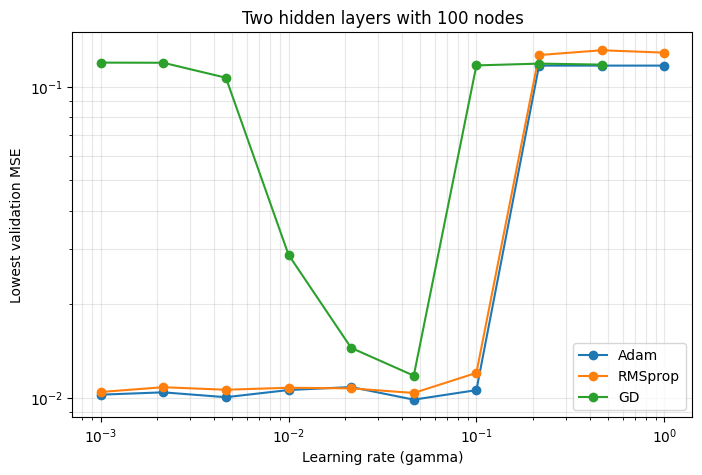

In [9]:
# Plot lowest validation MSE vs learning rate
fig, ax = plt.subplots(figsize=(8, 5))

for optimizer_name, best_mses in results.items():
    best_mses = np.array(best_mses)

    # Only plot valid MSE values below 1
    mask = np.isfinite(best_mses) & (best_mses < 1)

    ax.plot(learning_rates[mask], best_mses[mask], marker="o", label=optimizer_name)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_ylim(top=0.15)
ax.set_xlabel("Learning rate (gamma)")
ax.set_ylabel("Lowest validation MSE")
ax.set_title("Two hidden layers with 100 nodes")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
fig.savefig(figures_dir / "part_b_learning_rate_1_100_100_1.pdf", bbox_inches="tight")
plt.show()

Sjekk test MSE for de beste
Beste for 1 hidden layer:
Adam     | M = 16   | gamma = 0.46416 | Best val MSE = 0.010864 | Epoch = 621

Beste for 2 hidden layers:
Adam     | M = 16   | gamma = 0.00464 | Best val MSE = 0.010036 | Epoch = 129

In [11]:
#Test MSE first architecture

layer_sizes = [1, 50, 1]
activations = ["sigmoid", "identity"]
gamma = learning_rates[8]
optimizer = Adam(gamma)
batch_size = 16
epochs = 621

nn_model = NeuralNetwork(layer_sizes, activations)
error_history = train(nn_model, optimizer, X_train, y_train, epochs, batch_size, X_val=X_val, y_val=y_val)

test_MSE = nn_model.cost(X_test, y_test)
print(f"Best test MSE: {test_MSE}")
print(f"Val MSE: {error_history['val'][-1]}") #check

Best test MSE: 0.015107709359283595
Val MSE: 0.010864382583624436


In [13]:
#Test MSE second architecture

layer_sizes = [1, 100, 100, 1]
activations = ["sigmoid", "sigmoid", "identity"]
gamma = learning_rates[2]
optimizer = Adam(gamma)
batch_size = 16
epochs = 129

nn_model = NeuralNetwork(layer_sizes, activations)
error_history = train(nn_model, optimizer, X_train, y_train, epochs, batch_size, X_val=X_val, y_val=y_val)

test_MSE = nn_model.cost(X_test, y_test)
print(f"Best test MSE: {test_MSE}")
print(f"Val MSE: {error_history['val'][-1]}") #check

Best test MSE: 0.012802182599838022
Val MSE: 0.010035788400380467
